# Exploratory data analysis

Walk-through of the processed dataset (`data/processed/*.parquet`). All tables and figures come from functions in `data/eda.py`; running `python -m data.eda` from the repo root regenerates the same outputs in `reports/eda/` without this notebook. This notebook adds the commentary used for the report.

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent)) # notebooks/ -> repo root

import pandas as pd
from IPython.display import display

from data import eda

%matplotlib inline
eda.OUT_DIR.mkdir(parents=True, exist_ok=True)
df = eda.load()
tabs = eda.tables(df)
eda.save_tables(tabs) # also writes the CSVs to reports/eda/

## 1. Class balance and splits

Natives are the smallest class (187 texts), and A1 and C2 are also small, so training should use class weights. AI texts (1,035) sit at about the size of the largest human class (B2, 922). The held-out generator (Qwen) appears only in `test_heldout_generator`.

In [2]:
display(tabs["class_counts_by_split"])

split,train,val,test,test_heldout_generator,Total
class,,,,,
A1,183,40,40,0,263
A2,395,84,84,0,563
B1,498,108,108,0,714
B2,646,138,138,0,922
C1,498,106,107,0,711
C2,194,42,42,0,278
native,132,28,27,0,187
ai,630,135,135,135,1035
Total,3176,681,681,135,4673


## 2. Task by class

Task and level are linked: 67% of A1 texts are the Frog story, while B2 and C1 are mostly Film and Chaplin. A model may partly learn the task as a proxy for the level, so per-task results are worth checking. AI texts follow the overall human task mix.

class,A1,A2,B1,B2,C1,C2,native,ai
prompt_id,,,,,,,,
T13,176,203,142,120,90,42,79,248
T14,44,124,259,378,292,129,73,387
T3,43,236,313,424,329,107,35,400


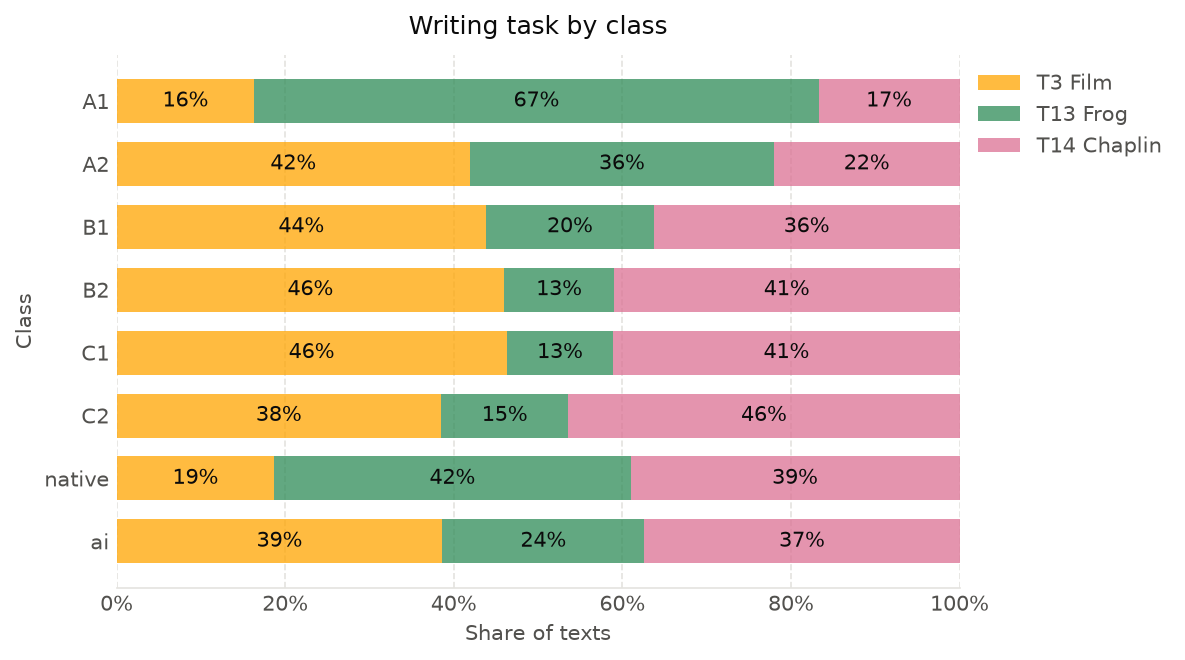

In [6]:
eda.plot_task_by_class(df)
display(tabs["task_by_class"])

## 3. Learner first language (L1)

75% of learner texts come from Spanish speakers, and L1 is also linked to level: almost all A1 texts are Spanish, while German writers are mostly C1 and C2. Results may not generalise to learners with other first languages.

class,A1,A2,B1,B2,C1,C2,native,Total
l1,,,,,,,,
Total,263,563,714,922,711,278,187,3638
Spanish,256,498,562,662,462,146,0,2586
Italian,0,13,83,119,67,6,0,288
German,0,0,7,58,124,90,0,279
English,0,0,0,0,0,0,187,187
Turkish,4,23,15,19,16,5,0,82
Chinese,2,11,24,23,16,4,0,80
Czech,1,14,14,20,12,18,0,79
Greek,0,2,8,16,11,3,0,40


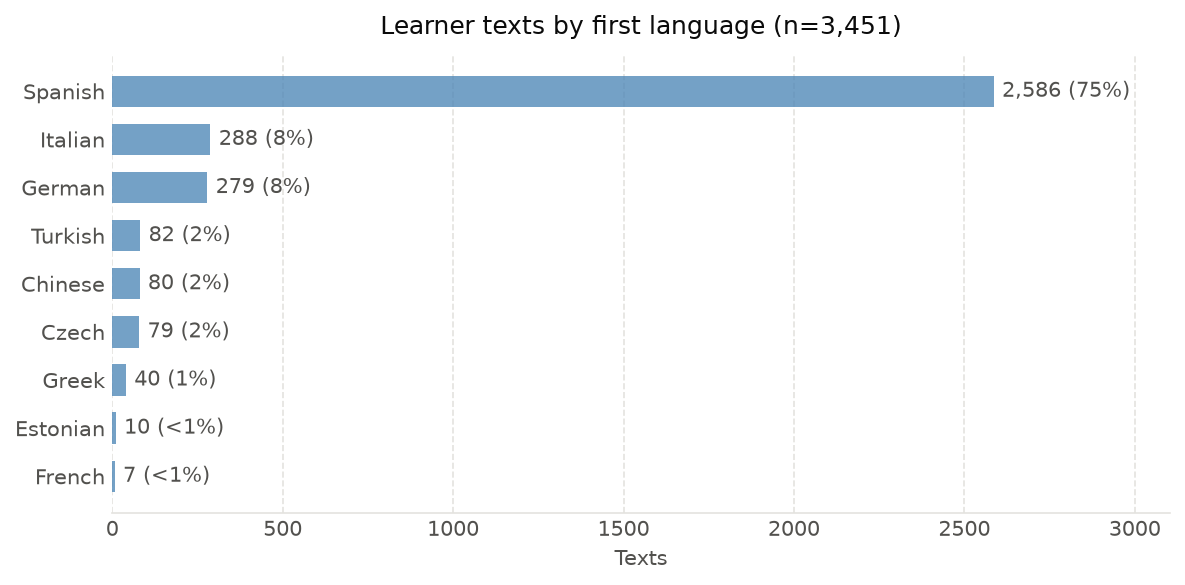

In [7]:
eda.plot_l1(df)
display(tabs["l1_by_class"])

## 4. Text length

Length rises steadily with proficiency (median 87 words at A1, 212 at C2). AI texts were sampled to match human lengths per task, so their median (153) sits mid-range.

,count,min,25%,50%,75%,max
class,,,,,,
A1,263.0,9.0,67.0,87.0,114.5,399.0
A2,563.0,9.0,89.5,110.0,149.5,558.0
B1,714.0,28.0,99.0,136.0,192.0,468.0
B2,922.0,69.0,108.0,155.0,214.0,947.0
C1,711.0,54.0,125.5,182.0,255.0,976.0
C2,278.0,72.0,135.2,211.5,289.8,931.0
native,187.0,44.0,133.5,194.0,258.5,686.0
ai,1035.0,50.0,110.0,153.0,216.5,774.0


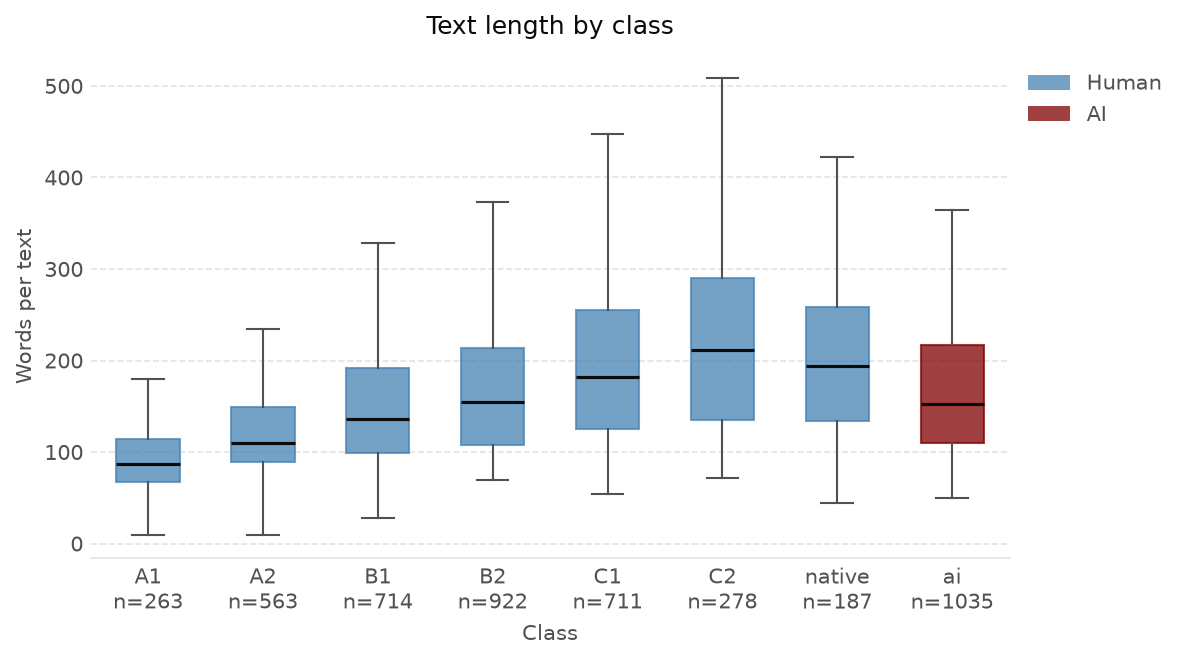

In [3]:
eda.plot_length(df)
display(tabs["words_by_class"])

## 5. Length by generator and task

Median words per text for each AI generator against human writing, per task.

In [8]:
display(tabs["median_words_by_source_task"])

prompt_id,T13,T14,T3
source_model,,,
gemini-3.5-flash-lite,186.0,167.0,128.0
human,142.0,193.0,114.0
openai/gpt-oss-120b,154.0,184.0,123.5
qwen/qwen3.8-27b,151.0,261.0,135.0


## 6. Vocabulary variety (type-token ratio)

TTR is computed on the first 50 words, because TTR falls as texts get longer; texts shorter than 50 words (30 A1, 7 A2, 1 B1, 2 native) are excluded. Human TTR rises from A1 (0.62) to C1 (0.78), so lower-proficiency writing is more repetitive, which is the property AI detectors may be confusing with machine text. AI text overall has the highest TTR (0.82).

,count,median,mean
class,,,
A1,233,0.62,0.626
A2,556,0.70,0.705
B1,713,0.74,0.739
B2,922,0.76,0.763
C1,711,0.78,0.771
C2,278,0.76,0.768
native,185,0.74,0.741
ai,1035,0.82,0.813


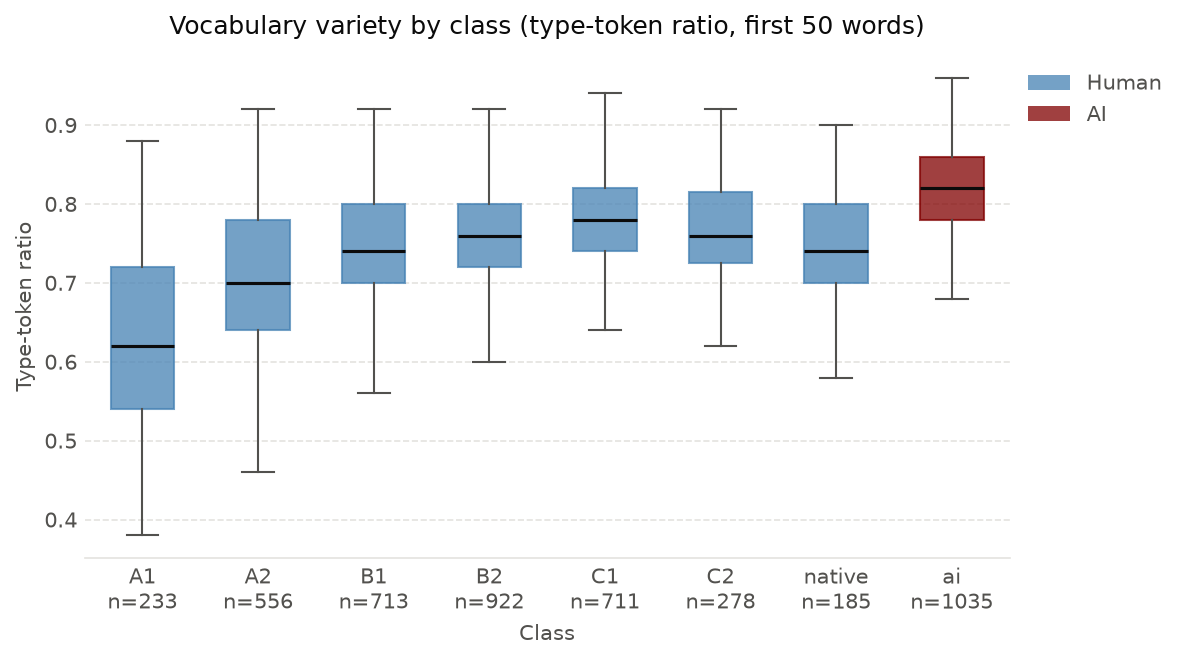

In [4]:
eda.plot_ttr(df)
display(tabs["ttr_by_class"])

## 7. AI text imitating learner levels

40% of AI texts were prompted to write like a learner at A2, B1, B2 or C1. Their TTR is close to real writers at the same level (A2: 0.72 vs 0.70; B1: 0.76 vs 0.74; B2: 0.78 vs 0.76), so simple, error-containing AI text resembles human writing at A2–B2. This is the "loophole" risk: thresholds loosened for low CEFR levels could let this text through, which is why the calibrated thresholds may need a floor. Learner-style AI texts are also longer than real A2 and B1 texts.

human                         ai_imitating                        
           n median_words median_ttr            n median_words median_ttr
A1       263         87.0       0.62         <NA>          NaN        NaN
A2       563        110.0       0.70          106        143.0       0.72
B1       714        136.0       0.74          112        166.5       0.76
B2       922        155.0       0.76          101        162.0       0.78
C1       711        182.0       0.78           94        164.0       0.84
C2       278        211.5       0.76         <NA>          NaN        NaN
native   187        194.0       0.74          622        150.0       0.84

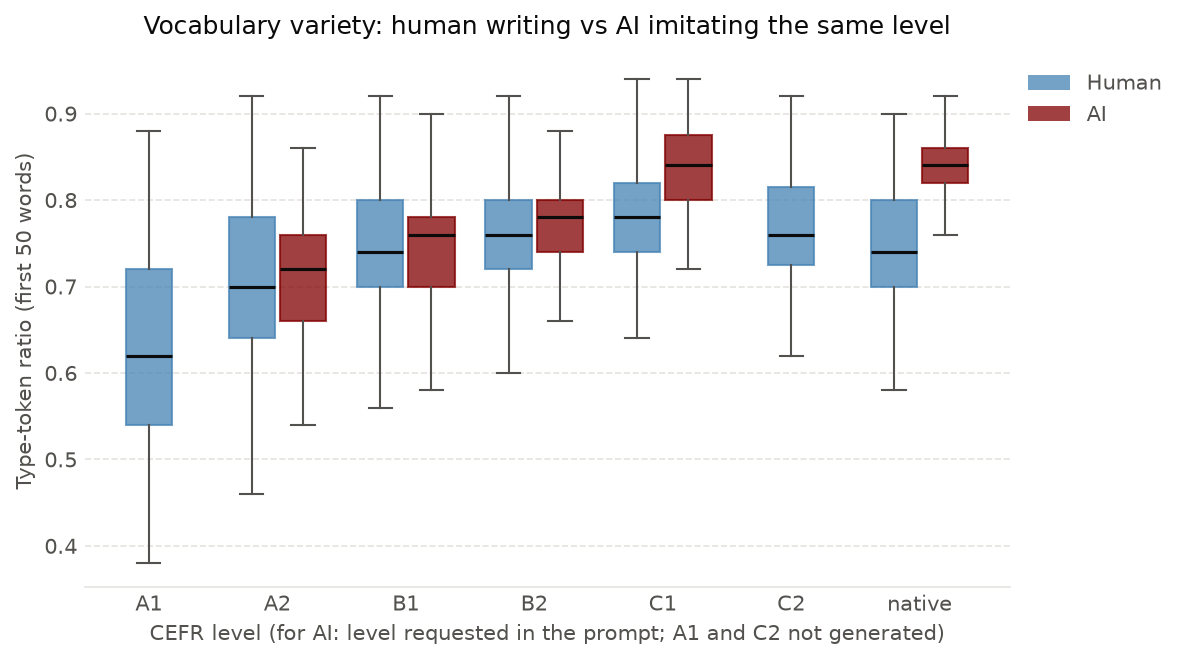

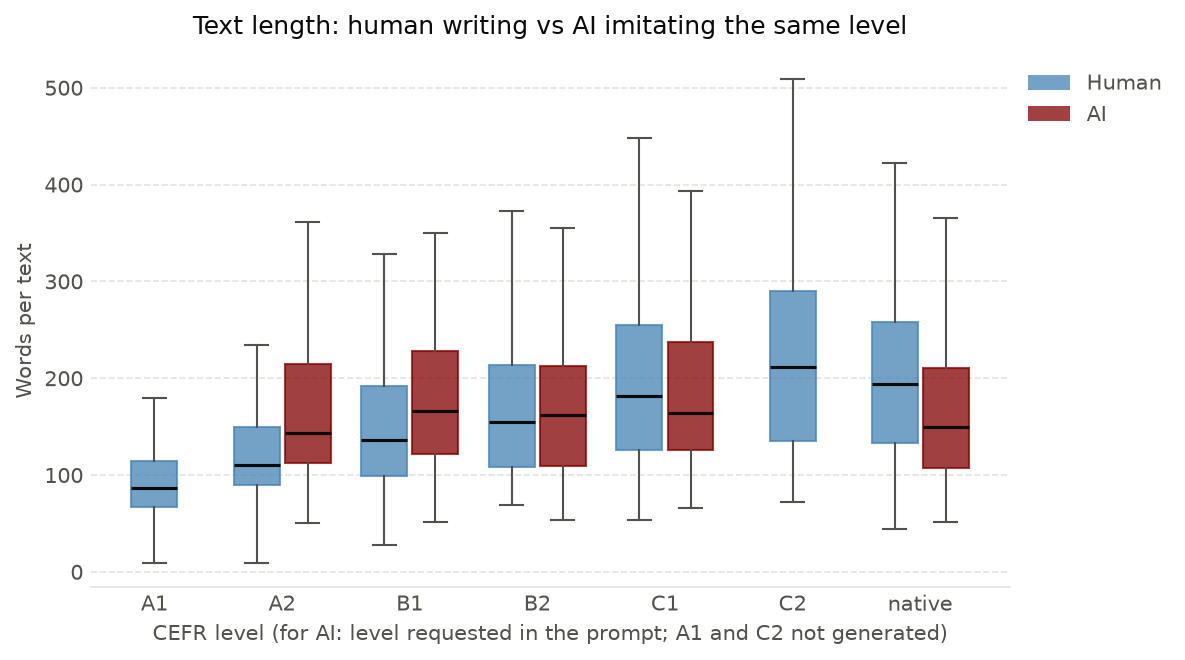

In [5]:
eda.plot_ai_style_ttr(df)
eda.plot_ai_style_length(df)
display(tabs["ai_style_vs_human"])